# Stage 5: Exploratory data analysis
Questions this notebook answers:
1. How imbalanced is the target, and what does that mean for evaluation?
2. Which customer and financial characteristics separate defaulters from good borrowers?
3. Which variables carry the most signal, and which might raise fairness concerns later?

Default rates are shown with each segment's **size**, because a risky but tiny segment matters less than a moderately
risky large one.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from credit_risk.config import get_paths, load_config
from credit_risk.features import build_application_features
from credit_risk.viz import COLORS, savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()

app = pd.read_parquet(paths["interim_data"] / "application_train_clean.parquet")
df = build_application_features(app)  # adds AGE_YEARS, ratios, EXT_SOURCE_MEAN, etc. for analysis
BASE = df["TARGET"].mean()
print(f"{len(df):,} applicants | portfolio default rate {BASE:.2%}")


def default_rate_by(col, data=df, top=None, min_count=30, sort=True):
    g = data.groupby(col, observed=True)["TARGET"].agg(applicants="size", default_rate="mean")
    g = g[g["applicants"] >= min_count]
    g["share"] = g["applicants"] / g["applicants"].sum()
    if sort:
        g = g.sort_values("default_rate", ascending=False)
    return g.head(top) if top else g


def plot_rate(g, title, ax, color=COLORS["bad"], horizontal=True):
    labels = g.index.astype(str)
    if horizontal:
        ax.barh(labels, 100 * g["default_rate"], color=color)
        ax.invert_yaxis()
        ax.axvline(100 * BASE, ls="--", color="grey", lw=1)
        for i, (r, s) in enumerate(zip(g["default_rate"], g["share"])):
            ax.text(100 * r + 0.2, i, f"{100 * r:.1f}%  (n={s:.0%})", va="center", fontsize=8)
        ax.set_xlabel("Default rate (%)")
        ax.set_xlim(0, 100 * g["default_rate"].max() * 1.35)
    else:
        ax.bar(labels, 100 * g["default_rate"], color=color)
        ax.axhline(100 * BASE, ls="--", color="grey", lw=1)
        ax.set_ylabel("Default rate (%)")
    ax.set_title(title)

307,511 applicants | portfolio default rate 8.07%


## 1. Target distribution

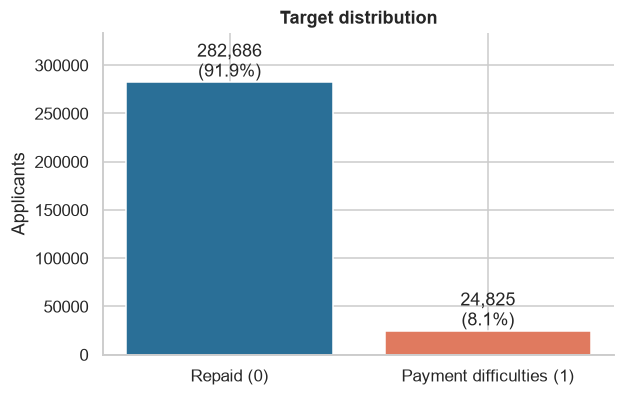

In [2]:
fig, ax = plt.subplots(figsize=(6, 3.8))
counts = df["TARGET"].value_counts().sort_index()
ax.bar(["Repaid (0)", "Payment difficulties (1)"], counts, color=[COLORS["good"], COLORS["bad"]])
for i, v in enumerate(counts):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set(title="Target distribution", ylabel="Applicants")
ax.set_ylim(0, counts.max() * 1.18)
savefig(fig, "eda_target_distribution")
plt.show()

**Implication:** a model that approves everyone is ~92% accurate on the full data and useless. We evaluate with
ROC-AUC / Gini, PR-AUC and KS, and choose the decision threshold from business costs (Stage 10), not 0.5.

## 2. Customer demographics

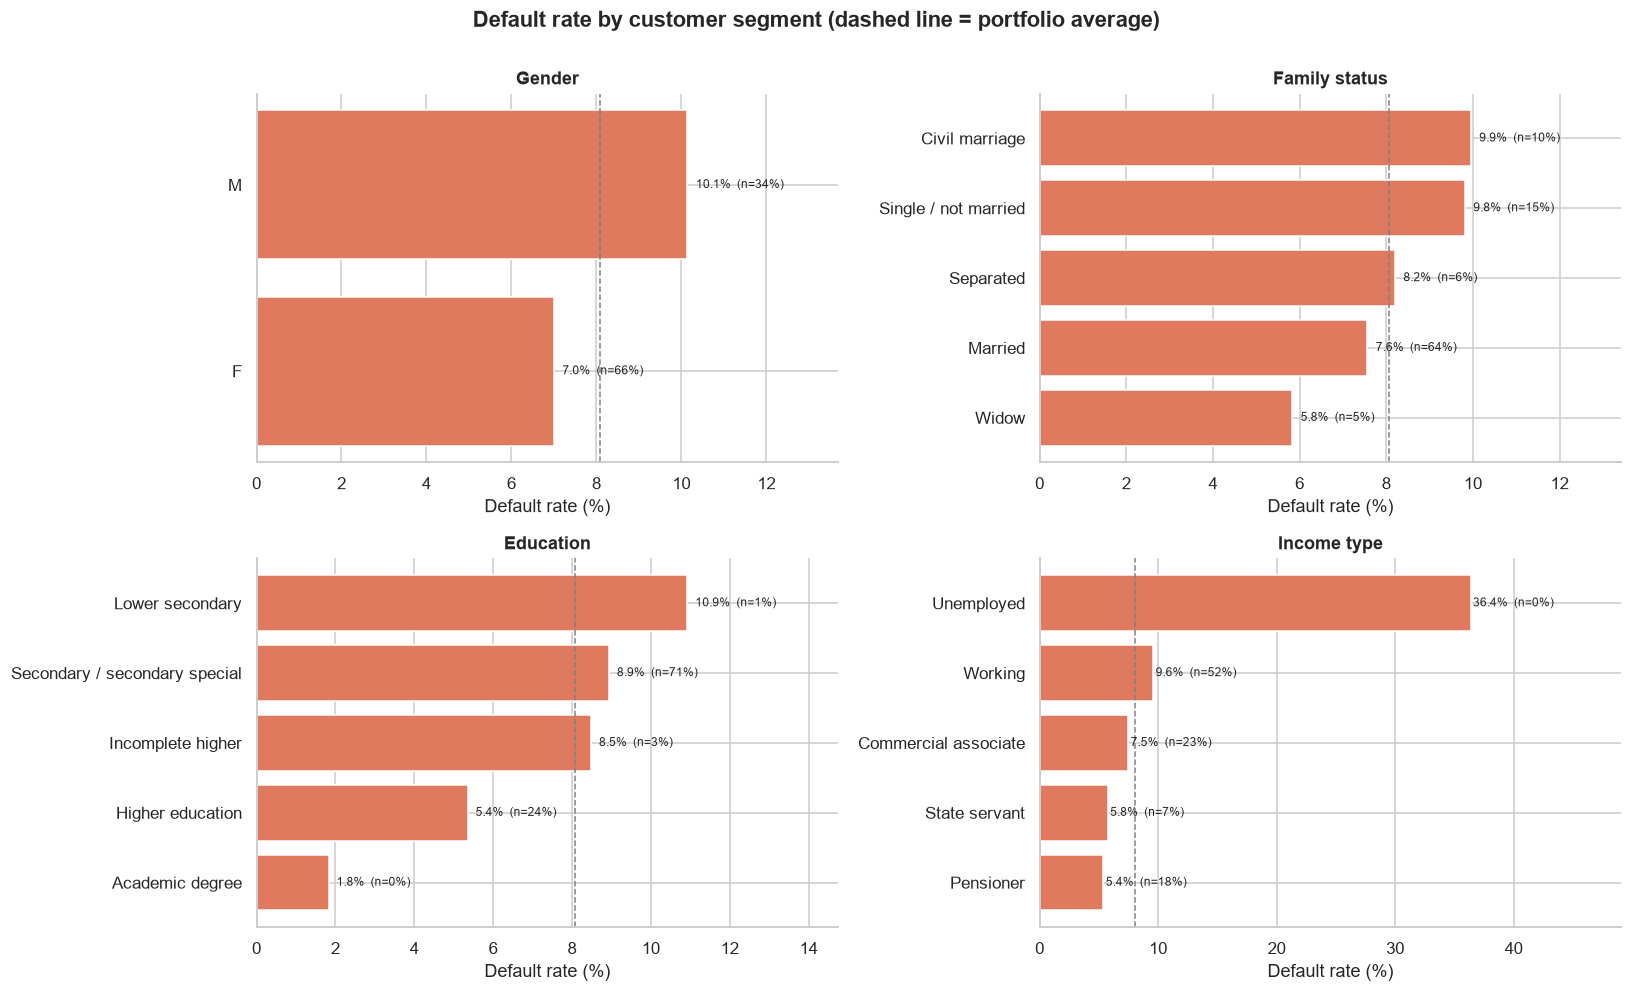

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
plot_rate(default_rate_by("CODE_GENDER"), "Gender", axes[0, 0])
plot_rate(default_rate_by("NAME_FAMILY_STATUS"), "Family status", axes[0, 1])
plot_rate(default_rate_by("NAME_EDUCATION_TYPE"), "Education", axes[1, 0])
plot_rate(default_rate_by("NAME_INCOME_TYPE", min_count=20), "Income type", axes[1, 1])
fig.suptitle("Default rate by customer segment (dashed line = portfolio average)", y=1.0, fontweight="bold")
fig.tight_layout()
savefig(fig, "eda_demographics")
plt.show()

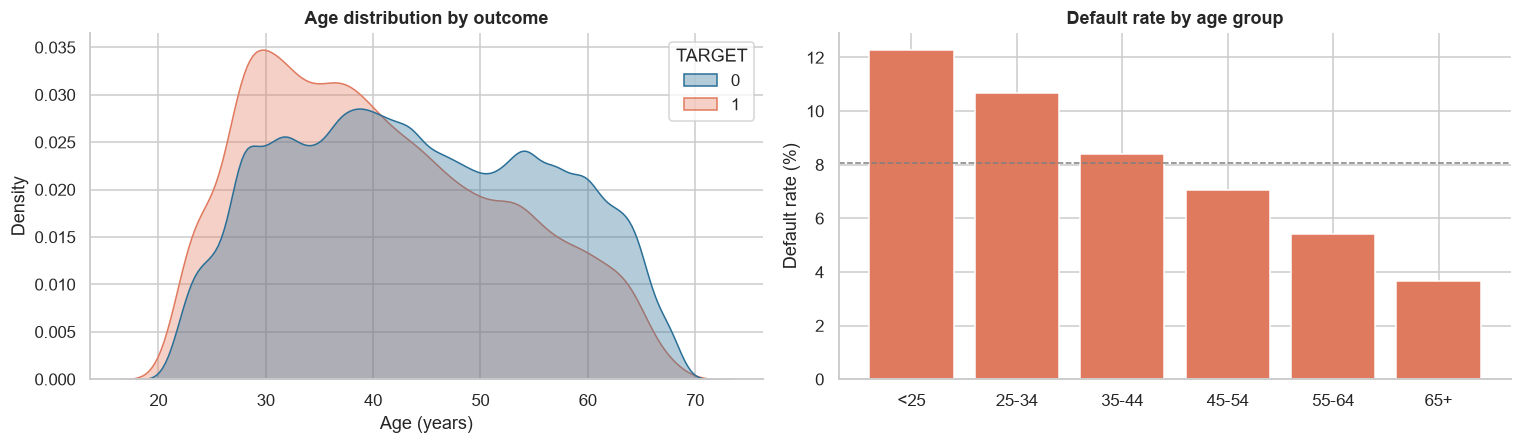

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.kdeplot(data=df, x="AGE_YEARS", hue="TARGET", common_norm=False, fill=True, alpha=0.35,
            palette=[COLORS["good"], COLORS["bad"]], ax=axes[0])
axes[0].set(title="Age distribution by outcome", xlabel="Age (years)")
g = default_rate_by("AGE_GROUP", sort=False).reindex(["<25", "25-34", "35-44", "45-54", "55-64", "65+"]).dropna()
plot_rate(g, "Default rate by age group", axes[1], horizontal=False)
fig.tight_layout()
savefig(fig, "eda_age")
plt.show()

Gender, family status and age are clearly predictive, and they are also **protected characteristics** in most lending
regulations. We note this now and deal with it in Stage 7 (gender and marital status excluded from the model) and Stage 12 (fairness testing).

## 3. Income and credit amounts

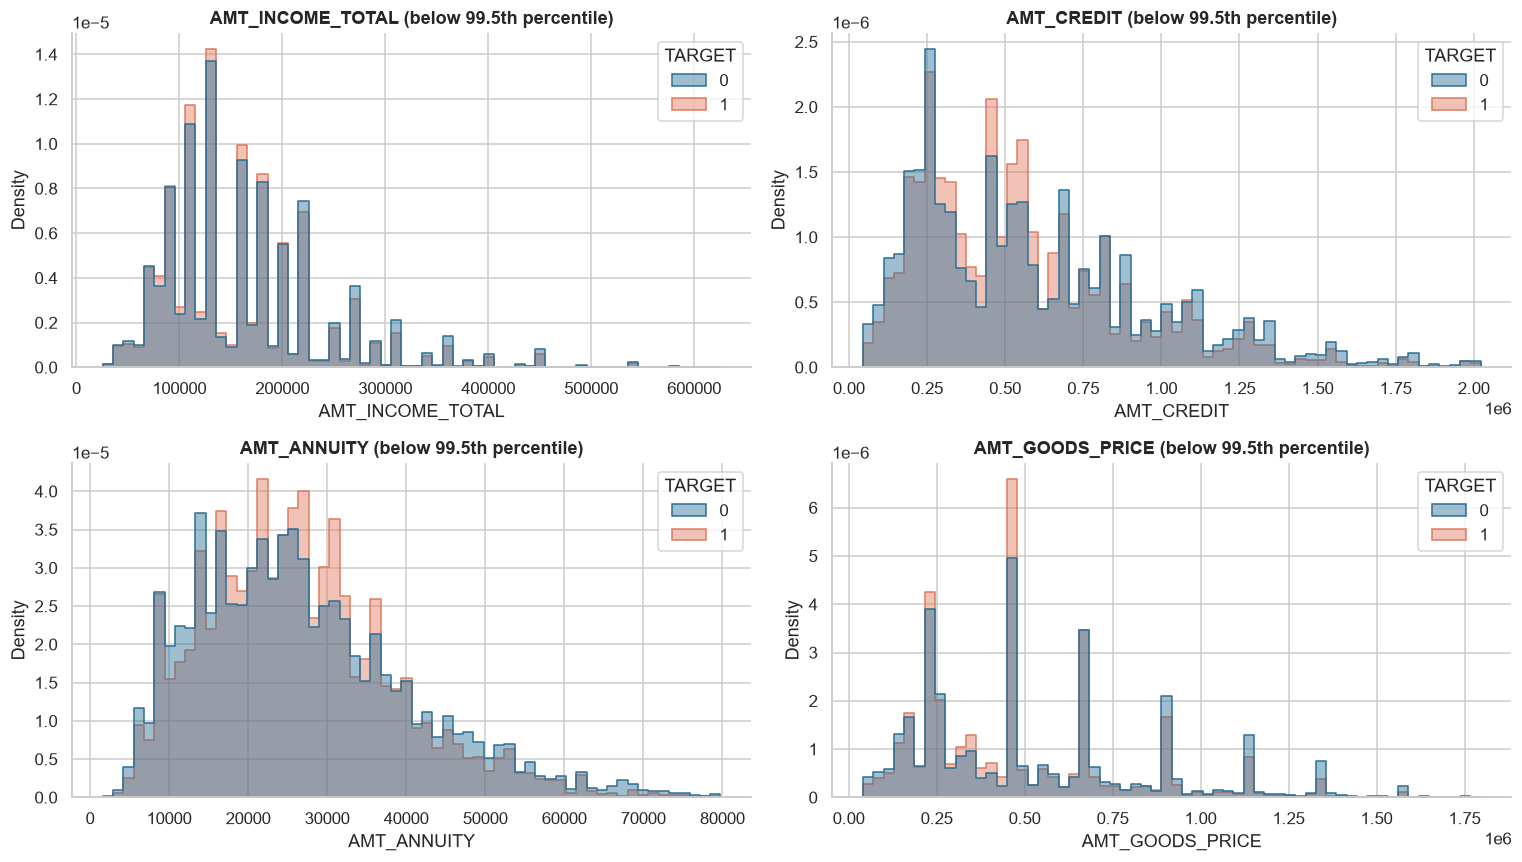

TARGET,median_repaid,median_default
AMT_INCOME_TOTAL,148500.0,135000.0
AMT_CREDIT,517788.0,497520.0
AMT_ANNUITY,24876.0,25263.0
AMT_GOODS_PRICE,450000.0,450000.0


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]):
    clip = df[col].quantile(0.995)
    sns.histplot(data=df[df[col] < clip], x=col, hue="TARGET", stat="density", common_norm=False, bins=60,
                 palette=[COLORS["good"], COLORS["bad"]], alpha=0.45, ax=ax, element="step")
    ax.set_title(f"{col} (below 99.5th percentile)")
fig.tight_layout()
savefig(fig, "eda_amounts")
plt.show()

df[["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]].groupby(df["TARGET"]).median().T.rename(columns={0: "median_repaid", 1: "median_default"})

Raw amounts separate defaulters surprisingly poorly. **Affordability ratios** carry more signal. One known Home Credit
quirk: mid-sized loans (where credit is close to the goods price) behave differently from small ones.

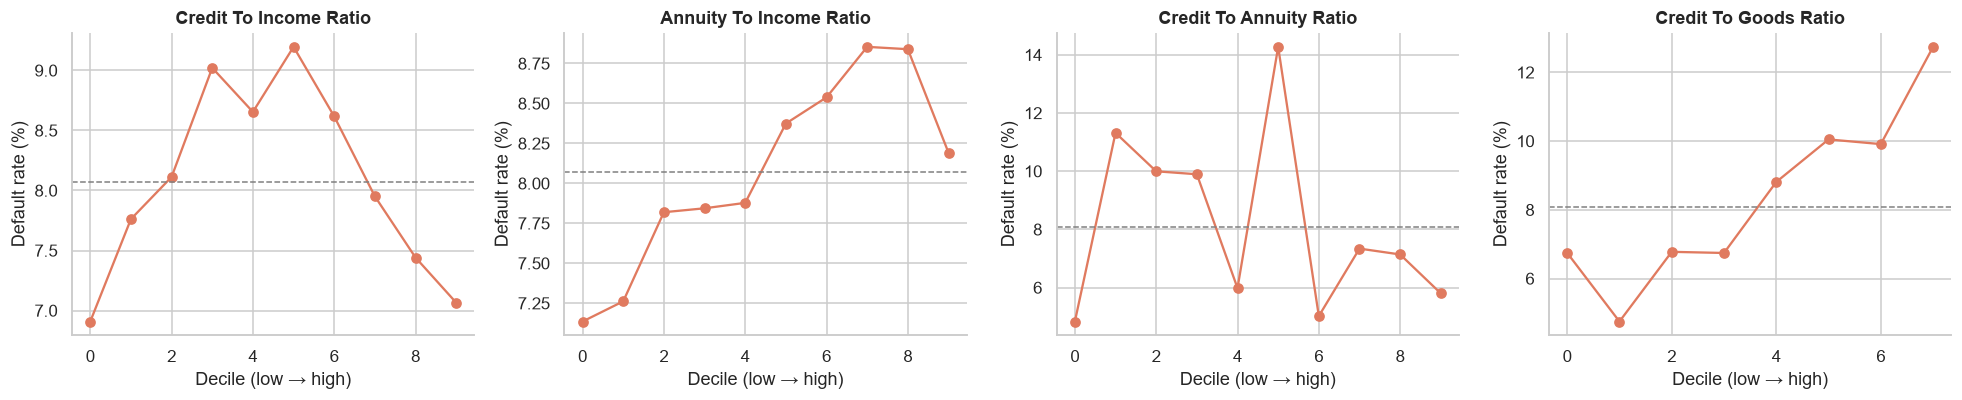

In [6]:
ratio_cols = ["CREDIT_TO_INCOME_RATIO", "ANNUITY_TO_INCOME_RATIO", "CREDIT_TO_ANNUITY_RATIO", "CREDIT_TO_GOODS_RATIO"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col in zip(axes, ratio_cols):
    q = pd.qcut(df[col], 10, duplicates="drop")
    r = df.groupby(q, observed=True)["TARGET"].mean() * 100
    ax.plot(range(len(r)), r.values, marker="o", color=COLORS["bad"])
    ax.axhline(100 * BASE, ls="--", color="grey", lw=1)
    ax.set(title=col.replace("_", " ").title(), xlabel="Decile (low → high)", ylabel="Default rate (%)")
fig.tight_layout()
savefig(fig, "eda_affordability_ratios")
plt.show()

## 4. External credit scores: the strongest single signals

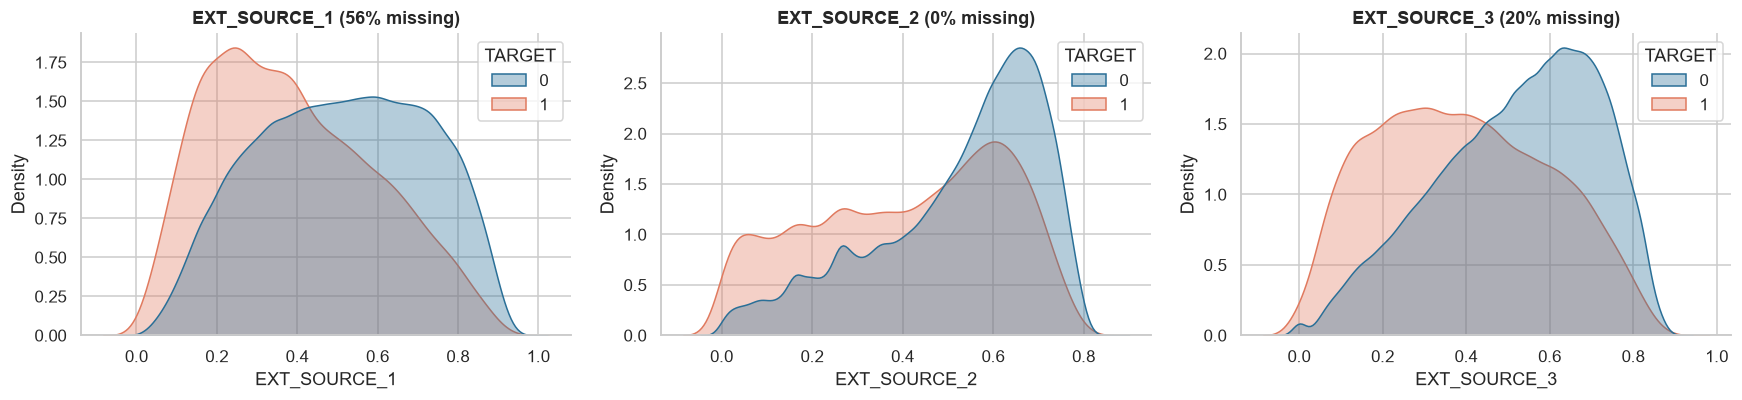

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=df, x=col, hue="TARGET", common_norm=False, fill=True, alpha=0.35,
                palette=[COLORS["good"], COLORS["bad"]], ax=ax)
    ax.set_title(f"{col} ({df[col].isna().mean():.0%} missing)")
fig.tight_layout()
savefig(fig, "eda_ext_sources")
plt.show()

## 5. Employment and occupation

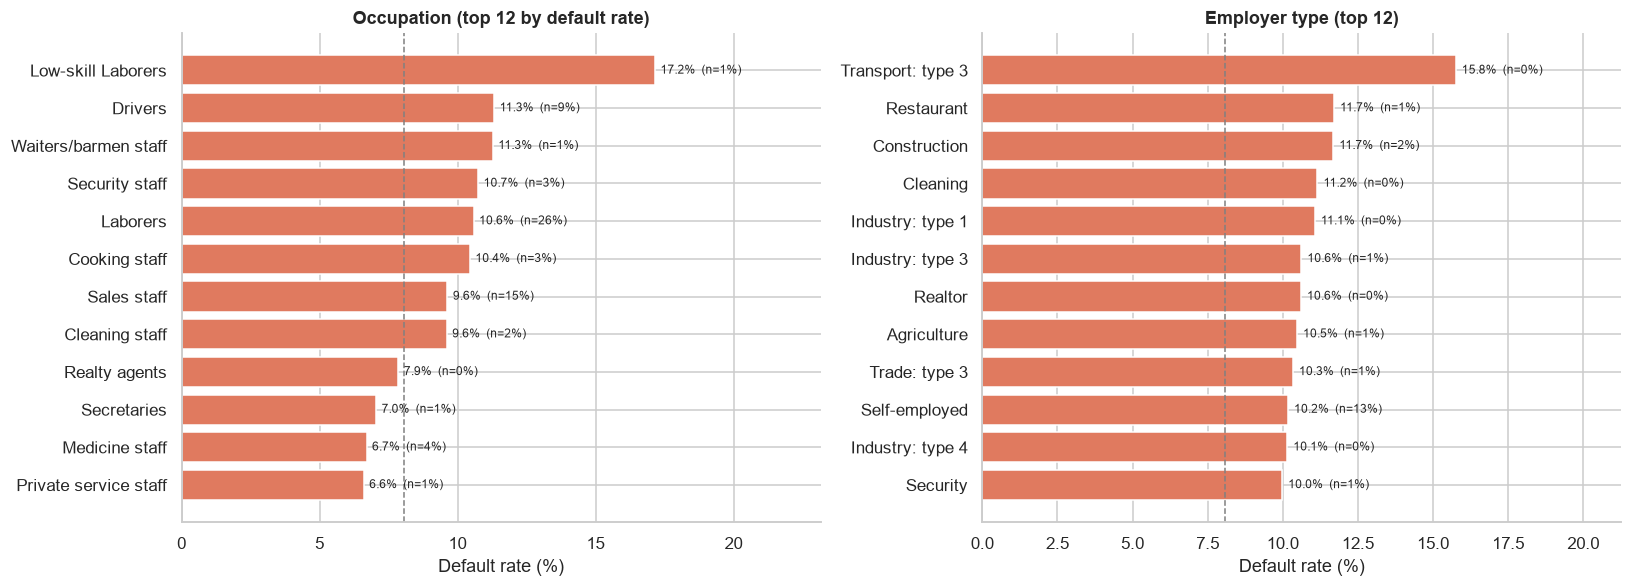

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_rate(default_rate_by("OCCUPATION_TYPE", top=12), "Occupation (top 12 by default rate)", axes[0])
plot_rate(default_rate_by("ORGANIZATION_TYPE", top=12, min_count=100), "Employer type (top 12)", axes[1])
fig.tight_layout()
savefig(fig, "eda_occupation")
plt.show()

## 6. Which numeric variables correlate most with default?
Spearman (rank) correlation is robust to the skewed amounts. Use it for screening only; the models capture
non-linear effects and interactions that correlations miss.

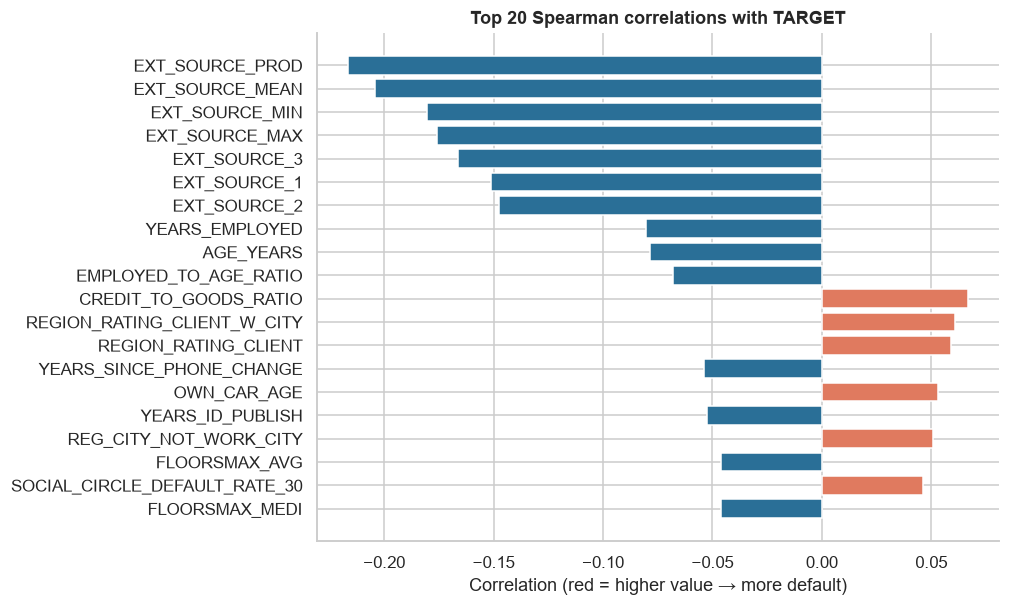

In [9]:
num = df.select_dtypes("number").drop(columns=["SK_ID_CURR", "TARGET"])
corr = num.corrwith(df["TARGET"], method="spearman").dropna().sort_values(key=np.abs, ascending=False)
top = corr.head(20)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] > 0, COLORS["bad"], COLORS["good"]))
ax.set(title="Top 20 Spearman correlations with TARGET", xlabel="Correlation (red = higher value → more default)")
savefig(fig, "eda_top_correlations")
plt.show()

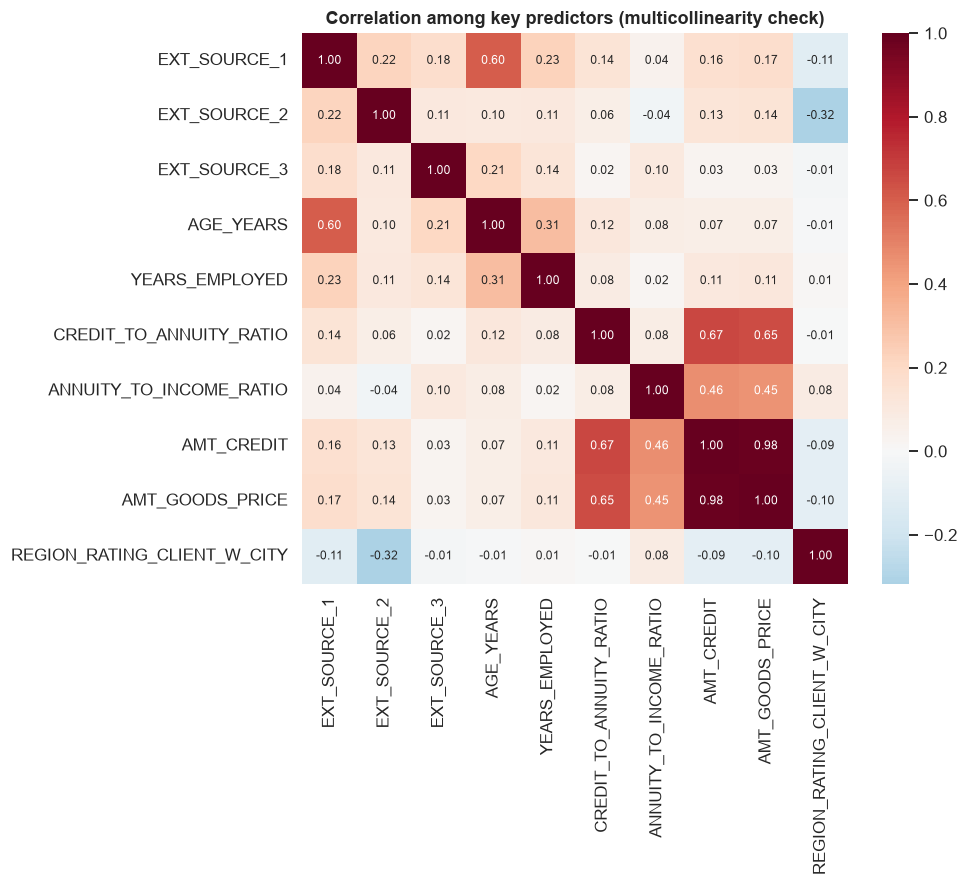

In [10]:
key = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AGE_YEARS", "YEARS_EMPLOYED", "CREDIT_TO_ANNUITY_RATIO",
       "ANNUITY_TO_INCOME_RATIO", "AMT_CREDIT", "AMT_GOODS_PRICE", "REGION_RATING_CLIENT_W_CITY"]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df[key].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation among key predictors (multicollinearity check)")
savefig(fig, "eda_multicollinearity")
plt.show()

`AMT_CREDIT` and `AMT_GOODS_PRICE` are almost perfectly correlated. Keeping both adds nothing for trees and
destabilises logistic-regression coefficients, so the correlation filter in Stage 7 removes one of each such pair.

## 7. Interactive view: risk by age and education (Plotly)

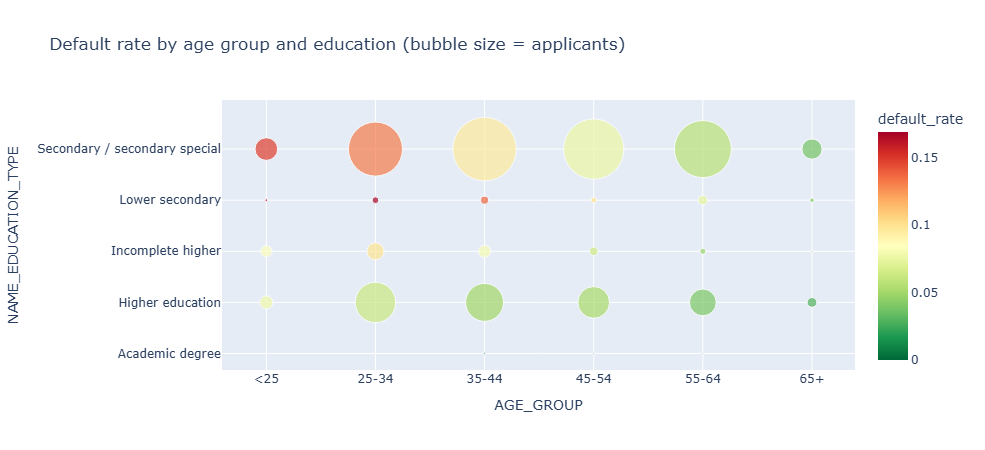

In [11]:
seg = (df.groupby(["AGE_GROUP", "NAME_EDUCATION_TYPE"], observed=True)["TARGET"]
         .agg(applicants="size", default_rate="mean").reset_index())
seg = seg[seg["applicants"] >= 30]
fig = px.scatter(seg, x="AGE_GROUP", y="NAME_EDUCATION_TYPE", size="applicants", color="default_rate",
                 color_continuous_scale="RdYlGn_r", size_max=45,
                 category_orders={"AGE_GROUP": ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]},
                 title="Default rate by age group and education (bubble size = applicants)")
fig.update_layout(height=450)
fig.write_html(paths["figures"] / "eda_age_education_interactive.html")
fig.show()

## Key EDA findings → modelling decisions
| Finding | Decision |
|---|---|
| Strong class imbalance | Class weights; evaluate with AUC/PR-AUC/KS; cost-based threshold |
| `EXT_SOURCE_*` are the strongest single predictors | Combine them (mean, min, product) and keep missing as information |
| Ratios beat raw amounts | Engineer affordability ratios (credit/income, annuity/income, credit/annuity, credit/goods) |
| Younger, less-educated, unstable-income applicants default more | Keep stability features; monitor protected/proxy attributes for fairness |
| Highly correlated pairs (credit ↔ goods price) | Correlation filter fitted on the training split |
| Past behaviour isn't in this table at all | Aggregate bureau, instalment and card history in Stage 6 |